# Customer Dialogue Analytics & SQL

**Project:** Banking Conversational AI Analytics 
**Focus:** Relational data modeling · KPI design · SQL validation · Customer journey friction analysis  
**Technology:** Python, pandas, DuckDB, matplotlib  
**Data:** **100% synthetic conversations, actions, and confidence scores** (not ING data)

### Business objective
Evaluate **where a virtual assistant fails**: (1) understanding an utterance, (2) executing a banking operation, or (3) resolving the customer's issue. Translate those findings into SQL metrics and operational recommendations.

This notebook continues Notebook 02, but does **not** load its trained classifier. The dialogue log, intent predictions, and confidence values below are **synthetic demonstration data**. Results must **not** be presented as observed chatbot performance or as Notebook 02 model metrics.

**Execution:** Run from the project's `notebooks/` directory using the project's `.venv` kernel. The notebook creates a separate demonstration database at `data/warehouse/dialogue_analytics_nb03_demo.duckdb`; it does not modify the earlier `dialogue_analytics.duckdb`. Re-running resets **only the three demonstration tables** in the separate database.

## 1. Business definitions and measurement grain

A **conversation** is one customer session; a **turn** is one customer message; an **action event** is one attempted banking operation. These are distinct measurement grains: a conversation can have several turns, and a turn can trigger several action attempts.

| KPI | Numerator | Denominator | Grain |
|---|---|---|---|
| Message-level Fallback Rate | Turns where `is_fallback = TRUE` | All recorded customer turns | Turn |
| Self-Service Resolution Rate (SSRR) | Eligible conversations labeled `bot_resolved` and with no agent handoff | All eligible conversations | Conversation |
| Action Success Rate | Action attempts with `action_status = 'success'` | All action attempts | Action event |
| Agent Handoff Rate | Conversations with `handoff_to_agent = TRUE` | All conversations | Conversation |
| Abandonment Rate | Conversations labeled `abandoned` | All conversations | Conversation |

**Synthetic business rules:** `is_eligible` and `resolution_status` are scenario-assigned labels. In a real bank, eligibility, resolution, consent, and handoff must be defined with product owners and verified from operational systems. A successful API action is **not necessarily** a resolved conversation. A fallback is not necessarily an unresolved conversation. There are no customer identifiers or personal banking records in this notebook.

## 2. Environment and isolated DuckDB connection

**Why:** An embedded analytical SQL engine lets us use primary/foreign keys, SQL aggregations, and persistent tables without setting up a server. We use a **dedicated demo database** to avoid touching any existing work.

Install once in your activated environment: `python -m pip install duckdb pandas matplotlib numpy`.

In [1]:
from pathlib import Path
from datetime import datetime, timedelta
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)

# Works whether VS Code starts the kernel in notebooks/ or project root.
working_dir = Path.cwd().resolve()
project_root = working_dir.parent if working_dir.name == "notebooks" else working_dir
db_dir = project_root / "data" / "warehouse"
db_dir.mkdir(parents=True, exist_ok=True)
db_path = db_dir / "dialogue_analytics_nb03_demo.duckdb"

# Close a connection left open by a previous interactive execution.
try:
    con.close()
except NameError:
    pass

con = duckdb.connect(str(db_path))
print("DuckDB version:", duckdb.__version__)
print("Demo database:", db_path)

DuckDB version: 2.0.0
Demo database: /Users/yaser/banking-conversational-ai-analytics/data/warehouse/dialogue_analytics_nb03_demo.duckdb


## 3. Database design and referential integrity

### 3.1 Entity relationships

`conversations (1) → (many) conversation_turns (1) → (many) action_events`

- `PRIMARY KEY`: one unique record ID per table.
- `FOREIGN KEY`: a turn cannot reference a missing conversation; an action cannot reference a missing turn.
- `CHECK` constraints: enforce allowed statuses and sensible confidence ranges.
- Re-running this notebook intentionally **recreates only the demo tables**, in child-to-parent order to respect foreign keys. No production data are used.

In [2]:
# Reset only tables in the separate NB03 demo database.
for table in ["action_events", "conversation_turns", "conversations"]:
    con.execute(f"DROP TABLE IF EXISTS {table}")

con.execute("""
CREATE TABLE conversations (
    conversation_id VARCHAR PRIMARY KEY,
    started_at TIMESTAMP NOT NULL,
    ended_at TIMESTAMP,
    is_eligible BOOLEAN NOT NULL,
    resolution_status VARCHAR NOT NULL
        CHECK (resolution_status IN ('bot_resolved', 'handoff', 'unresolved', 'abandoned')),
    handoff_to_agent BOOLEAN NOT NULL,
    CHECK (ended_at IS NULL OR ended_at >= started_at),
    CHECK (resolution_status != 'bot_resolved' OR handoff_to_agent = FALSE)
)
""")

con.execute("""
CREATE TABLE conversation_turns (
    turn_id VARCHAR PRIMARY KEY,
    conversation_id VARCHAR NOT NULL REFERENCES conversations(conversation_id),
    turn_number INTEGER NOT NULL CHECK (turn_number > 0),
    utterance_text VARCHAR NOT NULL,
    predicted_intent VARCHAR,
    confidence_score DOUBLE CHECK (confidence_score BETWEEN 0 AND 1),
    is_fallback BOOLEAN NOT NULL,
    UNIQUE (conversation_id, turn_number)
)
""")

con.execute("""
CREATE TABLE action_events (
    action_id VARCHAR PRIMARY KEY,
    turn_id VARCHAR NOT NULL REFERENCES conversation_turns(turn_id),
    action_name VARCHAR NOT NULL,
    action_status VARCHAR NOT NULL CHECK (action_status IN ('success', 'failed')),
    error_code VARCHAR,
    CHECK (
        (action_status = 'success' AND error_code IS NULL)
        OR (action_status = 'failed' AND error_code IS NOT NULL)
    )
)
""")

print("Created tables:")
display(con.execute("SHOW TABLES").df())

Created tables:


,name
0,action_events
1,conversation_turns
2,conversations


### 3.2 Inspect the schema

**Why:** Validate that expected columns and data types exist **before** loading any data. This prevents downstream SQL from silently using an incorrect structure.

In [3]:
schema = con.execute("""
SELECT table_name, column_name, data_type, is_nullable
FROM information_schema.columns
WHERE table_schema = 'main'
  AND table_name IN ('conversations', 'conversation_turns', 'action_events')
ORDER BY table_name, ordinal_position
""").df()
display(schema)

,table_name,column_name,data_type,is_nullable
0,action_events,action_id,VARCHAR,NO
1,action_events,turn_id,VARCHAR,NO
2,action_events,action_name,VARCHAR,NO
3,action_events,action_status,VARCHAR,NO
4,action_events,error_code,VARCHAR,YES
5,conversation_turns,turn_id,VARCHAR,NO
6,conversation_turns,conversation_id,VARCHAR,NO
7,conversation_turns,turn_number,INTEGER,NO
8,conversation_turns,utterance_text,VARCHAR,NO
9,conversation_turns,predicted_intent,VARCHAR,YES


## 4. Three curated synthetic customer journeys

These are the **same three scenarios** used during our step-by-step SQL exercise. We start with small, auditable records so that each numerator and denominator can be verified by hand.

| Session | Scenario | Conversation outcome | Action outcome |
|---|---|---|---|
| C001 | Deposit not reflected in balance | `bot_resolved` | Successful lookup |
| C002 | Stolen-card report after unclear first message | `handoff` | No action attempted |
| C003 | Pending transfer | `unresolved` | Bank API timeout |

All utterances, confidence values, actions, and outcomes here are **invented for education**. The first C002 turn uses a synthetic confidence of `0.22` to demonstrate the fallback threshold of `0.40`.

In [4]:
# Parent table first: conversations
con.execute("""
INSERT INTO conversations VALUES
('C001', '2026-10-22 09:00:00', '2026-10-22 09:03:00', TRUE, 'bot_resolved', FALSE),
('C002', '2026-10-22 09:10:00', '2026-10-22 09:15:00', TRUE, 'handoff', TRUE),
('C003', '2026-10-22 09:20:00', '2026-10-22 09:24:00', TRUE, 'unresolved', FALSE)
""")

# Then customer utterances: C002 contains two messages.
con.execute("""
INSERT INTO conversation_turns VALUES
('T001', 'C001', 1,
 'I deposited cash but my balance has not updated',
 'balance_not_updated_after_cheque_or_cash_deposit', 0.92, FALSE),
('T002', 'C002', 1,
 'I need help with my card',
 'card_not_working', 0.22, TRUE),
('T003', 'C002', 2,
 'My card was stolen today',
 'lost_or_stolen_card', 0.91, FALSE),
('T004', 'C003', 1,
 'My bank transfer is still pending',
 'pending_bank_transfer', 0.84, FALSE)
""")

# Finally attempted banking operations. C002 has no action event.
con.execute("""
INSERT INTO action_events VALUES
('A001', 'T001', 'check_deposit_status', 'success', NULL),
('A002', 'T004', 'check_transfer_status', 'failed', 'TIMEOUT')
""")

for table in ["conversations", "conversation_turns", "action_events"]:
    count = con.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
    print(f"{table}: {count:,} rows")

conversations: 3 rows
conversation_turns: 4 rows
action_events: 2 rows


## 5. Why a JOIN can duplicate conversations

A left join operates at the **turn grain** when one conversation has multiple messages. Thus three conversations produce **four joined rows**. Avoid `COUNT(*)` for conversation counts after a one-to-many join unless that is really the metric you intend.

In [5]:
journey_preview = con.execute("""
SELECT
    c.conversation_id,
    t.turn_number,
    t.utterance_text,
    t.predicted_intent,
    t.confidence_score,
    t.is_fallback,
    c.resolution_status
FROM conversations AS c
LEFT JOIN conversation_turns AS t
    ON c.conversation_id = t.conversation_id
ORDER BY c.conversation_id, t.turn_number
""").df()
display(journey_preview)

join_counts = con.execute("""
SELECT
    COUNT(*) AS joined_rows,
    COUNT(DISTINCT c.conversation_id) AS distinct_conversations
FROM conversations AS c
LEFT JOIN conversation_turns AS t
    ON c.conversation_id = t.conversation_id
""").df()
display(join_counts)

assert len(journey_preview) == 4
assert join_counts.loc[0, "distinct_conversations"] == 3

,conversation_id,turn_number,utterance_text,predicted_intent,confidence_score,is_fallback,resolution_status
0,C001,1,I deposited cash but my balance has not updated,balance_not_updated_after_cheque_or_cash_deposit,0.92,False,bot_resolved
1,C002,1,I need help with my card,card_not_working,0.22,True,handoff
2,C002,2,My card was stolen today,lost_or_stolen_card,0.91,False,handoff
3,C003,1,My bank transfer is still pending,pending_bank_transfer,0.84,False,unresolved


,joined_rows,distinct_conversations
0,4,3


## 6. KPI definitions — verified on the 3-session toy sample

### 6.1 Message-level Fallback Rate

$$	ext{Fallback Rate} = 
rac{	ext{fallback customer turns}}{	ext{all customer turns}} 	imes 100$$

The denominator is **messages**, not sessions. We record the candidate intent even when confidence is too low to accept automatically. A real system might instead use explicit `no_match` event logs.

In [6]:
toy_fallback = con.execute("""
SELECT
    COUNT(*) AS total_turns,
    COUNT(*) FILTER (WHERE is_fallback = TRUE) AS fallback_turns,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE is_fallback = TRUE)
        / NULLIF(COUNT(*), 0), 2
    ) AS fallback_rate_pct
FROM conversation_turns
""").df()
display(toy_fallback)
assert float(toy_fallback.loc[0, "fallback_rate_pct"]) == 25.0

,total_turns,fallback_turns,fallback_rate_pct
0,4,1,25.0


### 6.2 Self-Service Resolution Rate

$$	ext{SSRR} = 
rac{	ext{eligible sessions resolved by bot without handoff}}{	ext{eligible sessions}} 	imes 100$$

**Avoid joining to `conversation_turns`** unless you aggregate back to one row per conversation. The resolution label in this demo is an assumed synthetic outcome; actual resolution requires trustworthy customer outcome events or a validated definition.

In [7]:
toy_ssrr = con.execute("""
SELECT
    COUNT(*) FILTER (WHERE is_eligible = TRUE) AS eligible_conversations,
    COUNT(*) FILTER (
        WHERE is_eligible = TRUE
          AND resolution_status = 'bot_resolved'
          AND handoff_to_agent = FALSE
    ) AS resolved_by_bot,
    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE is_eligible = TRUE
              AND resolution_status = 'bot_resolved'
              AND handoff_to_agent = FALSE
        ) / NULLIF(COUNT(*) FILTER (WHERE is_eligible = TRUE), 0),
        2
    ) AS self_service_resolution_rate_pct
FROM conversations
""").df()
display(toy_ssrr)
assert float(toy_ssrr.loc[0, "self_service_resolution_rate_pct"]) == 33.33

,eligible_conversations,resolved_by_bot,self_service_resolution_rate_pct
0,3,1,33.33


### 6.3 Action Success Rate

$$	ext{Action Success Rate} = 
rac{	ext{successful action attempts}}{	ext{all action attempts}} 	imes 100$$

A failed action is an **execution** issue, not proof that intent recognition failed. An action retry counts as a separate attempt. Conversations with zero actions do not enter this denominator.

In [8]:
toy_action = con.execute("""
SELECT
    COUNT(*) AS total_actions,
    COUNT(*) FILTER (WHERE action_status = 'success') AS successful_actions,
    COUNT(*) FILTER (WHERE action_status = 'failed') AS failed_actions,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE action_status = 'success')
        / NULLIF(COUNT(*), 0), 2
    ) AS action_success_rate_pct
FROM action_events
""").df()
display(toy_action)
assert float(toy_action.loc[0, "action_success_rate_pct"]) == 50.0

,total_actions,successful_actions,failed_actions,action_success_rate_pct
0,2,1,1,50.0


### 6.4 Unit-test the small example

**Why:** Known toy numbers form a simple regression test. If later edits cause these expected values to change, investigate before scaling up.

In [9]:
assert con.execute("SELECT COUNT(*) FROM conversations").fetchone()[0] == 3
assert con.execute("SELECT COUNT(*) FROM conversation_turns").fetchone()[0] == 4
assert con.execute("SELECT COUNT(*) FROM action_events").fetchone()[0] == 2
assert toy_fallback.loc[0, "fallback_turns"] == 1
assert toy_ssrr.loc[0, "resolved_by_bot"] == 1
assert toy_action.loc[0, "successful_actions"] == 1
print("All toy-example checks passed.")

All toy-example checks passed.


## 7. Expand to a reproducible synthetic workload

The 3-session toy sample is too small for useful segmentation. We now **append 300 simulated sessions** with a fixed random seed; these represent **assumed scenarios, not discovered behavioral patterns**.

**Scenario-generation assumptions:**

- Eight banking topics have hand-written example customer messages.
- Each simulated session contains 1–4 turns.
- Synthetic confidence values are drawn from illustrative distributions, **not** Notebook 02's `predict_proba()`.
- `is_fallback` is set using an **illustrative** `confidence_score < 0.40` rule.
- An action can succeed, fail, or be retried. Some informational conversations need no banking action.
- Eligibility, handoff, abandonment, and resolution statuses are generated using transparent rules below. These are **not estimates of bank behavior or causal relationships**.

This section intentionally leaves the original three sessions unchanged, so earlier toy queries still document the initial exercise, but any newly-run KPI query will include the expanded data.

In [10]:
rng = np.random.default_rng(42)
SIMULATED_SESSIONS = 300
SIMULATED_THRESHOLD = 0.40

# All text and scenario choices below are fictional educational examples.
scenario_utterances = {
    "balance_not_updated_after_cheque_or_cash_deposit": [
        "My cash deposit has not appeared in my balance.",
        "I deposited money but the account balance hasn't changed.",
    ],
    "lost_or_stolen_card": [
        "My debit card was stolen. What should I do?",
        "I can't find my card and want to secure my account.",
    ],
    "pending_bank_transfer": [
        "My bank transfer is still pending.",
        "The transfer hasn't reached the recipient yet.",
    ],
    "virtual_card_not_working": [
        "My virtual card is not working online.",
        "The disposable virtual card keeps getting rejected.",
    ],
    "card_acceptance": [
        "Where can I use my debit card?",
        "Will merchants accept this card abroad?",
    ],
    "card_arrival": [
        "When will my replacement card arrive?",
        "I haven't received my new card yet.",
    ],
    "compromised_card": [
        "There is a suspicious card transaction on my account.",
        "I think somebody has used my card details.",
    ],
    "cash_withdrawal_charge": [
        "Why was I charged for withdrawing cash?",
        "The ATM charged a cash withdrawal fee.",
    ],
}

# Illustrative wrong-intent alternatives; not measured confusion rates.
confusion_examples = {
    "balance_not_updated_after_cheque_or_cash_deposit": "balance_not_updated_after_bank_transfer",
    "lost_or_stolen_card": "compromised_card",
    "pending_bank_transfer": "declined_transfer",
    "virtual_card_not_working": "getting_virtual_card",
    "card_acceptance": "card_not_working",
    "card_arrival": "card_delivery_estimate",
    "compromised_card": "lost_or_stolen_card",
    "cash_withdrawal_charge": "card_payment_fee_charged",
}

follow_up_utterances = [
    "Can you check that again, please?",
    "I'm still having this problem.",
    "I need more information about this issue.",
]

# Topic names describe the generator's intent, not ground-truth model labels.
scenario_names = list(scenario_utterances)
conversation_rows = []
turn_rows = []
action_rows = []

base_time = datetime(2026, 10, 1, 8, 0, 0)

### 7.1 Generate session, turn, and action records

We build rows in Python first and then insert them in **parent → child** order to comply with foreign keys. The same random seed creates the same demonstration data on every Run All.

In [11]:
for i in range(1, SIMULATED_SESSIONS + 1):
    conversation_id = f"S{i:04d}"
    topic = str(rng.choice(scenario_names))
    n_turns = int(rng.choice([1, 2, 3, 4], p=[0.62, 0.23, 0.11, 0.04]))
    started_at = base_time + timedelta(minutes=int(rng.integers(0, 14 * 24 * 60)))
    ended_at = started_at + timedelta(minutes=int(rng.integers(1, 15)))
    is_eligible = bool(rng.random() < 0.94)

    any_fallback = False
    last_turn_id = ""
    for turn_number in range(1, n_turns + 1):
        turn_id = f"{conversation_id}_T{turn_number:02d}"
        last_turn_id = turn_id
        utterance = (
            str(rng.choice(scenario_utterances[topic]))
            if turn_number == 1
            else str(rng.choice(follow_up_utterances))
        )

        # Deliberate synthetic scoring, NOT predictions from Notebook 02.
        if topic == "virtual_card_not_working":
            confidence = float(rng.beta(2.3, 3.7))
        else:
            confidence = float(rng.beta(4.2, 2.7))
        is_fallback = confidence < SIMULATED_THRESHOLD
        any_fallback = any_fallback or is_fallback
        predicted = (
            topic if rng.random() < 0.85
            else confusion_examples[topic]
        )
        turn_rows.append((
            turn_id, conversation_id, turn_number, utterance,
            predicted, round(confidence, 5), bool(is_fallback)
        ))

    # Some requests are information-only; others trigger a bank API operation.
    informational_topic = topic in {"card_acceptance", "card_arrival"}
    action_probability = 0.30 if informational_topic else 0.78
    final_action_status = None

    if rng.random() < action_probability:
        # Attempt(s) are linked to the final customer turn in this simplified log.
        action_name = {
            "lost_or_stolen_card": "freeze_card_request",
            "pending_bank_transfer": "check_transfer_status",
            "virtual_card_not_working": "check_virtual_card_status",
            "balance_not_updated_after_cheque_or_cash_deposit": "check_deposit_status",
            "compromised_card": "review_suspicious_transaction",
        }.get(topic, "check_customer_request")

        succeeded = bool(rng.random() < (0.65 if any_fallback else 0.82))
        final_action_status = "success" if succeeded else "failed"
        error_code = None if succeeded else str(rng.choice(
            ["TIMEOUT", "AUTH_FAILED", "SERVICE_UNAVAILABLE"]
        ))
        action_rows.append((
            f"{conversation_id}_A01", last_turn_id, action_name,
            final_action_status, error_code
        ))

        # Some failed actions are retried; an action attempt is its own KPI row.
        if not succeeded and rng.random() < 0.22:
            retry_succeeded = bool(rng.random() < 0.55)
            final_action_status = "success" if retry_succeeded else "failed"
            retry_error = None if retry_succeeded else "RETRY_TIMEOUT"
            action_rows.append((
                f"{conversation_id}_A02", last_turn_id, action_name,
                final_action_status, retry_error
            ))

    # Artificial outcome rules: no real customer journey is observed.
    if rng.random() < 0.06:
        resolution_status = "abandoned"
    elif not is_eligible:
        resolution_status = "handoff"
    elif final_action_status == "failed":
        resolution_status = "handoff" if rng.random() < 0.60 else "unresolved"
    elif any_fallback and rng.random() < 0.40:
        resolution_status = "handoff"
    elif topic == "lost_or_stolen_card" and rng.random() < 0.25:
        resolution_status = "handoff"
    else:
        resolution_status = "bot_resolved" if rng.random() < 0.82 else "unresolved"

    handoff_to_agent = resolution_status == "handoff"
    conversation_rows.append((
        conversation_id, started_at, ended_at, is_eligible,
        resolution_status, handoff_to_agent
    ))

print("Generated synthetic conversations:", len(conversation_rows))
print("Generated synthetic customer turns:", len(turn_rows))
print("Generated synthetic action attempts:", len(action_rows))

Generated synthetic conversations: 300
Generated synthetic customer turns: 505
Generated synthetic action attempts: 206


In [12]:
# Insert in dependency order; placeholders keep values and SQL separate.
con.executemany(
    "INSERT INTO conversations VALUES (?, ?, ?, ?, ?, ?)",
    conversation_rows
)
con.executemany(
    "INSERT INTO conversation_turns VALUES (?, ?, ?, ?, ?, ?, ?)",
    turn_rows
)
con.executemany(
    "INSERT INTO action_events VALUES (?, ?, ?, ?, ?)",
    action_rows
)

counts = con.execute("""
SELECT
    (SELECT COUNT(*) FROM conversations) AS conversations,
    (SELECT COUNT(*) FROM conversation_turns) AS customer_turns,
    (SELECT COUNT(*) FROM action_events) AS action_attempts
""").df()
display(counts)
assert int(counts.loc[0, "conversations"]) == SIMULATED_SESSIONS + 3

,conversations,customer_turns,action_attempts
0,303,509,208


## 8. Data quality validation

Before reporting KPI values, check referential integrity, duplicate identifiers, negative durations, out-of-range confidence values, and whether the toy routing decision matches the synthetic threshold. **Foreign keys block many orphans on insert; explicit checks document data quality for analysts and future pipeline changes.**

In [13]:
quality_checks = con.execute("""
SELECT
    (SELECT COUNT(*) - COUNT(DISTINCT conversation_id) FROM conversations)
        AS duplicate_conversation_ids,
    (SELECT COUNT(*) - COUNT(DISTINCT turn_id) FROM conversation_turns)
        AS duplicate_turn_ids,
    (SELECT COUNT(*) - COUNT(DISTINCT action_id) FROM action_events)
        AS duplicate_action_ids,
    (SELECT COUNT(*) FROM conversation_turns t
       LEFT JOIN conversations c ON t.conversation_id = c.conversation_id
       WHERE c.conversation_id IS NULL) AS orphan_turns,
    (SELECT COUNT(*) FROM action_events a
       LEFT JOIN conversation_turns t ON a.turn_id = t.turn_id
       WHERE t.turn_id IS NULL) AS orphan_actions,
    (SELECT COUNT(*) FROM conversations
       WHERE ended_at < started_at) AS negative_duration_sessions,
    (SELECT COUNT(*) FROM conversation_turns
       WHERE confidence_score NOT BETWEEN 0 AND 1 OR confidence_score IS NULL)
        AS invalid_confidence_turns,
    (SELECT COUNT(*) FROM conversation_turns
       WHERE is_fallback != (confidence_score < 0.40))
        AS fallback_rule_mismatches
""").df()
display(quality_checks.T.rename(columns={0: "issue_count"}))
assert int(quality_checks.to_numpy().sum()) == 0

,issue_count
duplicate_conversation_ids,0
duplicate_turn_ids,0
duplicate_action_ids,0
orphan_turns,0
orphan_actions,0
negative_duration_sessions,0
invalid_confidence_turns,0
fallback_rule_mismatches,0


### 8.1 Validate outcome consistency

This is **not** proof of real resolution quality. It simply checks that the **synthetic labels** do not contradict their own definitions.

In [14]:
status_quality = con.execute("""
SELECT
    COUNT(*) FILTER (
        WHERE resolution_status = 'bot_resolved' AND handoff_to_agent = TRUE
    ) AS resolved_but_handed_off,
    COUNT(*) FILTER (
        WHERE resolution_status = 'handoff' AND handoff_to_agent = FALSE
    ) AS handoff_status_without_flag,
    COUNT(*) FILTER (
        WHERE ended_at IS NULL
    ) AS missing_end_timestamps
FROM conversations
""").df()
display(status_quality)
assert status_quality.iloc[0]["resolved_but_handed_off"] == 0
assert status_quality.iloc[0]["handoff_status_without_flag"] == 0

,resolved_but_handed_off,handoff_status_without_flag,missing_end_timestamps
0,0,0,0


## 9. Build a one-row-per-conversation analytical view

**Why:** `conversations`, `conversation_turns`, and `action_events` have different grains. Directly joining all three can multiply rows. Aggregate turns and actions **separately to the conversation grain**, then join these aggregates to the parent table.

This view is a reusable analytics layer for SQL reports and a future BI dashboard.

In [15]:
con.execute("""
CREATE OR REPLACE VIEW v_conversation_metrics AS
WITH turn_agg AS (
    SELECT
        conversation_id,
        COUNT(*) AS turn_count,
        COUNT(*) FILTER (WHERE is_fallback = TRUE) AS fallback_turn_count,
        AVG(confidence_score) AS avg_confidence
    FROM conversation_turns
    GROUP BY conversation_id
),
action_agg AS (
    SELECT
        t.conversation_id,
        COUNT(*) AS action_attempt_count,
        COUNT(*) FILTER (WHERE a.action_status = 'success') AS successful_action_count,
        COUNT(*) FILTER (WHERE a.action_status = 'failed') AS failed_action_count
    FROM action_events a
    JOIN conversation_turns t ON a.turn_id = t.turn_id
    GROUP BY t.conversation_id
)
SELECT
    c.*,
    COALESCE(t.turn_count, 0) AS turn_count,
    COALESCE(t.fallback_turn_count, 0) AS fallback_turn_count,
    t.avg_confidence,
    COALESCE(a.action_attempt_count, 0) AS action_attempt_count,
    COALESCE(a.successful_action_count, 0) AS successful_action_count,
    COALESCE(a.failed_action_count, 0) AS failed_action_count
FROM conversations c
LEFT JOIN turn_agg t ON c.conversation_id = t.conversation_id
LEFT JOIN action_agg a ON c.conversation_id = a.conversation_id
""")

display(con.execute("""
SELECT * FROM v_conversation_metrics
ORDER BY conversation_id LIMIT 10
""").df())

# A view at the conversation grain must have exactly one row per conversation.
assert con.execute("SELECT COUNT(*) FROM v_conversation_metrics").fetchone()[0] ==        con.execute("SELECT COUNT(*) FROM conversations").fetchone()[0]

,conversation_id,started_at,ended_at,is_eligible,resolution_status,handoff_to_agent,turn_count,fallback_turn_count,avg_confidence,action_attempt_count,successful_action_count,failed_action_count
0,C001,2026-10-22 09:00:00,2026-10-22 09:03:00,True,bot_resolved,False,1,0,0.920000,1,1,0
1,C002,2026-10-22 09:10:00,2026-10-22 09:15:00,True,handoff,True,2,1,0.565000,0,0,0
2,C003,2026-10-22 09:20:00,2026-10-22 09:24:00,True,unresolved,False,1,0,0.840000,1,0,1
3,S0001,2026-10-12 04:02:00,2026-10-12 04:09:00,True,unresolved,False,1,0,0.637880,0,0,0
4,S0002,2026-10-07 12:59:00,2026-10-07 13:01:00,True,bot_resolved,False,1,0,0.736910,0,0,0
5,S0003,2026-10-07 20:49:00,2026-10-07 20:57:00,True,bot_resolved,False,1,0,0.460720,1,1,0
6,S0004,2026-10-12 23:46:00,2026-10-12 23:48:00,True,handoff,True,2,0,0.574965,1,1,0
7,S0005,2026-10-10 11:53:00,2026-10-10 12:00:00,True,bot_resolved,False,2,0,0.563890,1,1,0
8,S0006,2026-10-12 07:23:00,2026-10-12 07:29:00,True,bot_resolved,False,2,0,0.575900,0,0,0
9,S0007,2026-10-06 03:06:00,2026-10-06 03:08:00,False,handoff,True,1,1,0.320140,1,1,0


## 10. Core SQL KPI scorecard — expanded synthetic data

Compute each KPI at its **correct grain**. A turn-based fallback rate, a conversation-based self-service resolution rate, and an action-based success rate are **not numerically interchangeable**.

In [16]:
kpi_scorecard = con.execute("""
WITH session_kpis AS (
    SELECT
        COUNT(*) AS conversations,
        COUNT(*) FILTER (WHERE is_eligible = TRUE) AS eligible_conversations,
        COUNT(*) FILTER (
            WHERE is_eligible = TRUE
              AND resolution_status = 'bot_resolved'
              AND handoff_to_agent = FALSE
        ) AS bot_resolved_eligible,
        COUNT(*) FILTER (WHERE handoff_to_agent = TRUE) AS handoff_conversations,
        COUNT(*) FILTER (WHERE resolution_status = 'abandoned') AS abandoned_conversations
    FROM conversations
),
turn_kpis AS (
    SELECT COUNT(*) AS turns,
           COUNT(*) FILTER (WHERE is_fallback = TRUE) AS fallback_turns
    FROM conversation_turns
),
action_kpis AS (
    SELECT COUNT(*) AS attempts,
           COUNT(*) FILTER (WHERE action_status = 'success') AS successful_attempts
    FROM action_events
)
SELECT
    s.conversations,
    t.turns,
    a.attempts,
    ROUND(100.0 * t.fallback_turns / NULLIF(t.turns, 0), 2) AS fallback_rate_pct,
    ROUND(100.0 * s.bot_resolved_eligible / NULLIF(s.eligible_conversations, 0), 2)
        AS self_service_resolution_rate_pct,
    ROUND(100.0 * a.successful_attempts / NULLIF(a.attempts, 0), 2)
        AS action_success_rate_pct,
    ROUND(100.0 * s.handoff_conversations / NULLIF(s.conversations, 0), 2)
        AS agent_handoff_rate_pct,
    ROUND(100.0 * s.abandoned_conversations / NULLIF(s.conversations, 0), 2)
        AS abandonment_rate_pct
FROM session_kpis s
CROSS JOIN turn_kpis t
CROSS JOIN action_kpis a
""").df()
display(kpi_scorecard)

,conversations,turns,attempts,fallback_rate_pct,self_service_resolution_rate_pct,action_success_rate_pct,agent_handoff_rate_pct,abandonment_rate_pct
0,303,509,208,20.43,56.16,79.33,23.43,6.6


### 10.1 Reconciliation check: aggregation at the proper grain

Verify that **turn totals** in the conversation-grain view reconcile to the raw turn table, and **action attempt totals** reconcile to the raw event table. This is a practical check against join multiplication.

In [17]:
reconciliation = con.execute("""
SELECT
    (SELECT SUM(turn_count) FROM v_conversation_metrics) AS turns_in_view,
    (SELECT COUNT(*) FROM conversation_turns) AS turns_in_raw_table,
    (SELECT SUM(action_attempt_count) FROM v_conversation_metrics) AS actions_in_view,
    (SELECT COUNT(*) FROM action_events) AS actions_in_raw_table
""").df()
display(reconciliation)
assert reconciliation.loc[0, "turns_in_view"] == reconciliation.loc[0, "turns_in_raw_table"]
assert reconciliation.loc[0, "actions_in_view"] == reconciliation.loc[0, "actions_in_raw_table"]

,turns_in_view,turns_in_raw_table,actions_in_view,actions_in_raw_table
0,509.0,509,208.0,208


## 11. Where does the customer journey break?

We can identify **friction signals**, but cannot claim causal drivers from a simulated dataset. This case study measures:

1. Which conversations include fallback turns?
2. How often do unresolved conversations have failed banking actions?
3. Which action failure codes appear most frequently?
4. Does a higher number of turns coincide with a different outcome distribution?

All rates below are descriptive for our artificial scenario generator.

### 11.1 Resolution status distribution and session length

,turn_count,resolution_status,conversations
0,1,abandoned,12
1,1,bot_resolved,93
2,1,handoff,35
3,1,unresolved,30
4,2,abandoned,4
5,2,bot_resolved,43
6,2,handoff,19
7,2,unresolved,13
8,3,abandoned,1
9,3,bot_resolved,20


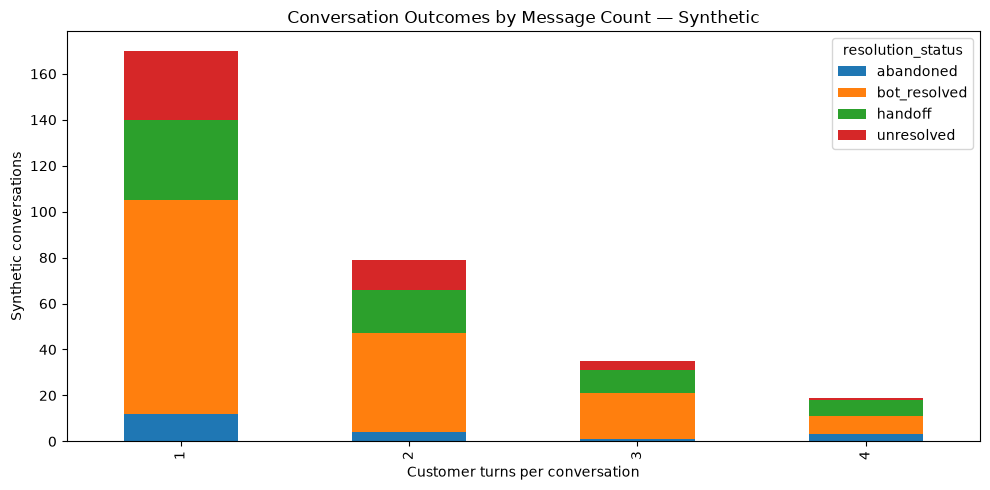

In [18]:
outcome_by_turn_count = con.execute("""
SELECT
    turn_count,
    resolution_status,
    COUNT(*) AS conversations
FROM v_conversation_metrics
GROUP BY turn_count, resolution_status
ORDER BY turn_count, resolution_status
""").df()
display(outcome_by_turn_count)

outcome_pivot = outcome_by_turn_count.pivot(
    index="turn_count", columns="resolution_status", values="conversations"
).fillna(0)
outcome_pivot.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.xlabel("Customer turns per conversation")
plt.ylabel("Synthetic conversations")
plt.title("Conversation Outcomes by Message Count — Synthetic")
plt.tight_layout()
plt.show()

### 11.2 Operational error-code analysis

**Why:** A failure such as `TIMEOUT` is an action-execution issue. In real bank data, this can be prioritized separately from intent-classification errors. Counting **action attempts** rather than sessions makes retry behavior visible.

In [19]:
action_failure_reasons = con.execute("""
SELECT
    a.action_name,
    a.error_code,
    COUNT(*) AS failed_attempts
FROM action_events a
WHERE a.action_status = 'failed'
GROUP BY a.action_name, a.error_code
ORDER BY failed_attempts DESC, a.action_name
""").df()
display(action_failure_reasons.head(15))

,action_name,error_code,failed_attempts
0,review_suspicious_transaction,TIMEOUT,6
1,check_customer_request,SERVICE_UNAVAILABLE,5
2,check_customer_request,TIMEOUT,5
3,check_deposit_status,SERVICE_UNAVAILABLE,3
4,check_deposit_status,AUTH_FAILED,3
5,check_virtual_card_status,AUTH_FAILED,3
6,check_transfer_status,SERVICE_UNAVAILABLE,2
7,check_transfer_status,TIMEOUT,2
8,check_virtual_card_status,SERVICE_UNAVAILABLE,2
9,freeze_card_request,SERVICE_UNAVAILABLE,2


### 11.3 Outcome analysis with and without fallback

A conversation may contain a fallback and **still** end as `bot_resolved`, because the bot could recover after asking a clarifying question. A high fallback share does not automatically imply low self-service resolution.

In [20]:
fallback_and_outcomes = con.execute("""
SELECT
    CASE WHEN fallback_turn_count > 0 THEN 'At least one fallback'
         ELSE 'No fallback' END AS fallback_group,
    COUNT(*) AS conversations,
    COUNT(*) FILTER (WHERE resolution_status = 'bot_resolved') AS bot_resolved,
    COUNT(*) FILTER (WHERE handoff_to_agent = TRUE) AS handoffs,
    COUNT(*) FILTER (WHERE resolution_status = 'unresolved') AS unresolved,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE handoff_to_agent = TRUE)
        / NULLIF(COUNT(*), 0), 2
    ) AS handoff_rate_pct
FROM v_conversation_metrics
GROUP BY 1
ORDER BY 1
""").df()
display(fallback_and_outcomes)

,fallback_group,conversations,bot_resolved,handoffs,unresolved,handoff_rate_pct
0,At least one fallback,90,30,42,10,46.67
1,No fallback,213,134,29,38,13.62


### 11.4 Intent-level friction (based on the **first predicted intent**)

**Why this choice?** Each conversation needs one grouping key to avoid multiplication in intent comparisons. We use its first predicted intent as a **convenient proxy**, not as confirmed customer intent. Predictions in this demo are synthetic and can be incorrect. A real analysis should use reviewed intent annotations and examine intent changes over time.

In [21]:
intent_friction = con.execute("""
WITH first_turn AS (
    SELECT
        conversation_id,
        predicted_intent AS first_predicted_intent
    FROM conversation_turns
    WHERE turn_number = 1
)
SELECT
    f.first_predicted_intent,
    COUNT(*) AS conversations,
    SUM(v.turn_count) AS customer_turns,
    SUM(v.fallback_turn_count) AS fallback_turns,
    ROUND(
        100.0 * SUM(v.fallback_turn_count)
        / NULLIF(SUM(v.turn_count), 0), 2
    ) AS fallback_rate_pct,
    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE v.is_eligible AND v.resolution_status = 'bot_resolved'
              AND NOT v.handoff_to_agent
        ) / NULLIF(COUNT(*) FILTER (WHERE v.is_eligible), 0), 2
    ) AS self_service_resolution_rate_pct,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE v.handoff_to_agent)
        / NULLIF(COUNT(*), 0), 2
    ) AS handoff_rate_pct
FROM v_conversation_metrics v
JOIN first_turn f ON v.conversation_id = f.conversation_id
GROUP BY f.first_predicted_intent
HAVING COUNT(*) >= 5
ORDER BY fallback_rate_pct DESC, conversations DESC
""").df()
display(intent_friction)

,first_predicted_intent,conversations,customer_turns,fallback_turns,fallback_rate_pct,self_service_resolution_rate_pct,handoff_rate_pct
0,virtual_card_not_working,46,77.0,40.0,51.95,51.11,23.91
1,declined_transfer,5,6.0,2.0,33.33,50.00,40.00
2,card_payment_fee_charged,6,10.0,3.0,30.00,66.67,16.67
3,lost_or_stolen_card,46,85.0,17.0,20.00,45.45,39.13
4,balance_not_updated_after_cheque_or_cash_deposit,34,52.0,8.0,15.38,64.52,20.59
5,pending_bank_transfer,33,61.0,9.0,14.75,65.63,21.21
6,card_arrival,23,35.0,5.0,14.29,52.17,8.70
7,card_delivery_estimate,5,7.0,1.0,14.29,40.00,20.00
8,compromised_card,27,48.0,6.0,12.50,59.26,33.33
9,cash_withdrawal_charge,31,53.0,6.0,11.32,56.67,19.35


### 11.5 Daily monitoring (synthetic dates)

A production dialogue dashboard usually tracks changes over time. Here the dates are artificially generated; the chart is **only a reporting technique demonstration**, not an actual bank trend.

,date,conversations,handoffs,handoff_rate_pct
0,2026-10-01,14,1,7.14
1,2026-10-02,25,6,24.00
2,2026-10-03,27,3,11.11
3,2026-10-04,18,3,16.67
4,2026-10-05,17,4,23.53
5,2026-10-06,26,4,15.38
6,2026-10-07,24,10,41.67
7,2026-10-08,18,4,22.22
8,2026-10-09,26,8,30.77
9,2026-10-10,21,5,23.81


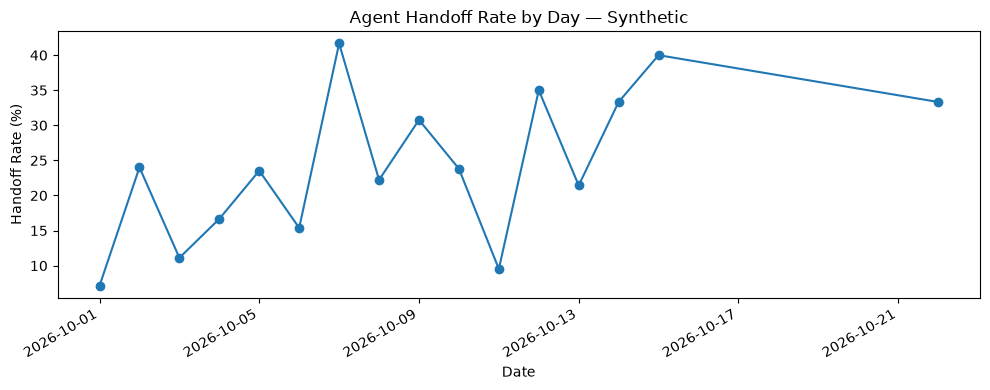

In [22]:
daily_kpis = con.execute("""
SELECT
    CAST(started_at AS DATE) AS date,
    COUNT(*) AS conversations,
    COUNT(*) FILTER (WHERE handoff_to_agent) AS handoffs,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE handoff_to_agent)
        / NULLIF(COUNT(*), 0), 2
    ) AS handoff_rate_pct
FROM conversations
GROUP BY 1
ORDER BY 1
""").df()
display(daily_kpis)

ax = daily_kpis.plot(
    x="date", y="handoff_rate_pct", marker="o", figsize=(10, 4), legend=False
)
ax.set_title("Agent Handoff Rate by Day — Synthetic")
ax.set_xlabel("Date")
ax.set_ylabel("Handoff Rate (%)")
plt.tight_layout()
plt.show()

## 12. Sanity checks, limitations, and recommendations

### 12.1 Key learning points

- **Metric grain matters.** Never calculate a session-level metric using `COUNT(*)` on a session-to-turn joined table without controlling multiplicity.
- **Root causes differ.** Intent mismatch, low confidence, an API timeout, handoff, and abandonment are different failure mechanisms.
- **Fallback ≠ resolution.** A fallback can be recovered by clarification; a correct intent can still lead to an unsuccessful API call.
- **Synthetic evidence ≠ business evidence.** Any pattern in this notebook is largely created by the generation assumptions; it should not be interpreted as a real customer insight.


## 13. Review questions (answer in your own words)

1. Why is `COUNT(DISTINCT conversation_id)` safer than `COUNT(*)` after joining conversations to turns?
2. If a banking API action succeeds but the customer abandons the chat, which KPI improves and which does not?
3. Why can two dashboards report different "fallback rates" even when both use the same event log?
4. Why are the high-friction intents discovered in this notebook **not** evidence of real banking-customer pain points?
5. What extra events would we need to distinguish an intent-recognition failure from an execution failure in production?

**Suggested portfolio summary (editable):** "Designed a DuckDB-based relational analytics layer for simulated banking assistant conversations, implemented message/session/action-level SQL KPIs, validated join cardinality and data quality, and developed friction analyses while clearly separating synthetic operations from real intent-classifier evaluation."